# 04 · Termómetros por bloque (PCA causal por bloque)

Construye y valida los **termómetros por bloque**: una PCA causal pequeña por bloque temático del pool de
features (8 bloques en la pista B, 5 en la A), reajustada cada mes solo con el pasado y con el signo fijado
por una columna ancla declarada a priori, para que el termómetro suba con el estrés. Cada termómetro es una
columna causal nueva del panel y forma el **menú T** de los detectores ([ADR-008](../docs/decisions/ADR-008-preregistro-pool-termometros.md)).

Aquí solo se hacen las validaciones **sin etiquetas de crisis** (`PendientesOscar.md` §6.5):

1. **Bien calculados**: factor plantado, prueba de prefijo, signo estable y NaN que no se propagan.
2. **Sentido estadístico y económico**: varianza de la PC1, peso máximo por columna, estabilidad de cargas
   y signos; elección del umbral de varianza entre 30, 40 y 50 %.
3. **Validez externa**: correlación con los índices de estrés `rol=validation` (NFCI, OFR_FSI, STLFSI4,
   KCFSI…), que nunca entran como features.

Las pruebas con crisis (relevancia, valor añadido y significación, puntos 4–6) vienen después, con los
detectores.

> **Prueba de humo (30-10-2026).** Ejecutado en un portátil sin `data/processed`: los paneles de las dos
> pistas se construyen **en memoria** con `regimenes.features.construir_paneles` (unos segundos) y **no se
> verifican contra los sha256** de `03_preprocesado`. Los crudos de esta máquina son una descarga anterior a
> ADR-003: faltan `SHILLER_SP500_CAPE` (`CAPE_z`) y las versiones multicolumna de `FF_5_INDUSTRY` y
> `FF_FACTORS_5_DAILY` (`FF_industry_dispersion_z`, `FF_RMW_z`). Esas 3 columnas quedan fuera, declaradas.
> Las cifras son orientativas; la versión oficial se ejecutará sobre `data/processed` verificado.

**Índice**

1. Bloques y anclas (pre-registro)
2. Validación 1 · bien calculados (datos de juguete)
3. Paneles de las pistas en memoria
4. Elección del umbral de varianza (sin etiquetas)
5. Termómetros de las dos pistas
6. Validación 2 · sentido estadístico y económico
7. Validación 3 · validez externa
8. Calentamiento: historia anterior a la ventana (punto abierto del ADR-008)
9. Conclusiones y pendientes

In [1]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import yaml
from IPython.display import display

warnings.filterwarnings('ignore')
plt.rcParams.update({'figure.dpi': 110, 'axes.grid': True, 'grid.alpha': .3, 'font.size': 9,
                     'axes.spines.top': False, 'axes.spines.right': False})

from regimenes import rutas
from regimenes import features as ft
from regimenes.features import bloques as bq

pd.set_option('display.max_colwidth', 120)
PARAMS = bq.parametros_bloques()
BLOQUES = {p: bq.cargar_bloques(p) for p in ('A', 'B')}
print('Parámetros del pre-registro:', PARAMS)

Parámetros del pre-registro: {'reajuste': 'mensual', 'min_obs': 252, 'ventana': None, 'umbrales_var_a_probar': [0.3, 0.4, 0.5]}


## 1. Bloques y anclas (pre-registro)

El reparto sale de [`configs/bloques.yaml`](../configs/bloques.yaml), que congela el ADR-008. Cada columna
del pool está en un único bloque; la ancla es una columna del bloque con el signo con el que se espera que
suba con el estrés. **Las anclas son propuesta** pendiente de aprobación.

In [2]:
filas = []
for pista, bloques in BLOQUES.items():
    for nombre, b in bloques.items():
        filas.append({'pista': pista, 'termometro': nombre, 'n_columnas': len(b['columnas']),
                      'ancla': b['ancla']['columna'], 'signo': b['ancla']['signo'],
                      'columnas': ', '.join(b['columnas'])})
tabla_bloques = pd.DataFrame(filas)
display(tabla_bloques)
print(tabla_bloques.groupby('pista')['n_columnas'].agg(['count', 'sum']))

,pista,termometro,n_columnas,ancla,signo,columnas
0,A,T1_renta_variable,7,SP500_vol_z,1,"SP500_ret_z, SP500_vol_z, SP500_momentum, SP500_drawdown, FF_MKT_z, FF_MOM_z, FF_industry_dispersion_z"
1,A,T2_tipos_nivel_curva,10,term_spread_hist_z,-1,"mid_curve_z, curve_vs_policy_10y_z, curve_vs_policy_5y_z, short_rate_z, TB3MS_z, GS1_z, GS5_z, GS10_z, term_spread_h..."
2,A,T3_velocidad_tipos,1,DGS10_change_z,1,DGS10_change_z
3,A,T6_credito,2,credit_BaaAaa_mensual_z,1,"credit_BaaAaa_mensual_z, credit_BaaFF_z"
4,A,T8_macro_valoracion,15,UNRATE_chg_z,1,"INDPRO_yoy_z, PPI_yoy_z, PPI_fuels_yoy_z, PPI_metals_yoy_z, CPI_yoy_z, CPI_core_yoy_z, UNRATE_chg_z, PAYEMS_chg_z, U..."
5,B,T1_renta_variable,14,SP500_vol_z,1,"SP500_ret_z, SP500_vol_z, SP500_momentum, SP500_drawdown, SP500_megacap_gap_z, equity_breadth_dispersion_z, smallcap..."
6,B,T2_tipos_nivel_curva,15,slope_10y3m_z,-1,"slope_10y2y_z, slope_10y3m_z, curve_curvature_z, mid_curve_z, curve_vs_policy_10y_z, curve_vs_policy_5y_z, short_rat..."
7,B,T3_velocidad_tipos,3,DGS10_change_z,1,"DGS10_change_z, DFII10_change_z, MOVE_change_z"
8,B,T4_inflacion_tipo_real,4,breakeven_10y_z,1,"DFII5_z, breakeven_10y_z, breakeven_5y_z, breakeven_5y_fwd_z"
9,B,T5_vol_implicita,7,VIX_level_z,1,"VIX_level_z, VIX_change_z, MOVE_level_z, VVIX_z, vix_term_z, vol_complex_dispersion_z, SKEW_z"


       count  sum
pista            
A          5   35
B          8   77


## 2. Validación 1 · bien calculados (datos de juguete)

Las mismas comprobaciones que `tests/features/test_bloques.py`, a la vista:

- **Factor plantado.** Seis columnas = carga × factor + ruido; el termómetro debe recuperar el factor.
- **Prefijo.** Calcular con el panel truncado en `t` da exactamente lo mismo hasta `t` que calcular con todo
  y recortar (`assert_causal`), con cortes a mitad de mes.
- **Signo.** La carga de la ancla mantiene el signo declarado en todos los reajustes.
- **NaN.** Una columna que empieza tarde y un NaN puntual no hacen NaN al termómetro.

Correlación termómetro-factor: 0.869
Primer valor: 2001-01-01 | NaN tras el primer valor: 0
Signo de la ancla en todos los reajustes: True
Días renormalizados por NaN puntual: 1


Prueba de prefijo OK en 4 cortes (tolerancia 1e-10)


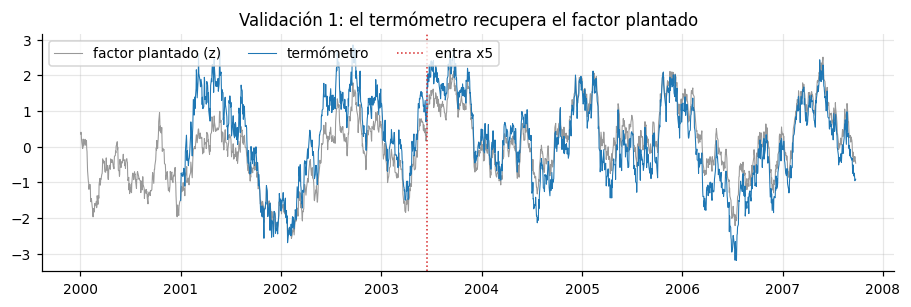

In [3]:
rng = np.random.default_rng(7)
idx = pd.bdate_range('2000-01-03', periods=252 * 8)
e = rng.normal(size=len(idx))
f = pd.Series(np.zeros(len(idx)), index=idx)
for i in range(1, len(idx)):
    f.iloc[i] = 0.98 * f.iloc[i - 1] + 0.2 * e[i]          # factor persistente y estacionario
cargas_plantadas = [1.0, 0.8, -0.6, 0.5, 0.9, -0.4]
juguete = pd.DataFrame({f'x{i}': c * f + rng.normal(scale=0.15, size=len(idx))
                        for i, c in enumerate(cargas_plantadas)}, index=idx)
juguete.loc[:idx[900], 'x5'] = np.nan          # columna que empieza tarde
juguete.loc[idx[1500], 'x1'] = np.nan          # NaN puntual
ancla = {'columna': 'x0', 'signo': 1}

t_jug, diag_jug = bq.termometro_bloque(juguete, list(juguete.columns), ancla, umbral_var=0.3)
validos = t_jug.dropna()
print(f'Correlación termómetro-factor: {validos.corr(f.loc[validos.index]):.3f}')
print('Primer valor:', validos.index[0].date(), '| NaN tras el primer valor:',
      int(t_jug.loc[validos.index[0]:].isna().sum()))
print('Signo de la ancla en todos los reajustes:',
      bool((diag_jug['carga_ancla'].dropna() > 0).all()))
print('Días renormalizados por NaN puntual:', int(diag_jug['n_dias_renormalizados'].fillna(0).sum()))

from regimenes.features.causalidad import assert_causal
cortes = [idx[700], idx[1111], idx[1500], idx[-30]]
for corte in cortes:
    completo = t_jug.loc[:corte]
    truncado, _ = bq.termometro_bloque(juguete.loc[:corte], list(juguete.columns), ancla, umbral_var=0.3)
    assert np.allclose(completo.values, truncado.values, atol=1e-10, equal_nan=True)
print('Prueba de prefijo OK en', len(cortes), 'cortes (tolerancia 1e-10)')

fig, ax = plt.subplots(figsize=(10, 2.8))
ax.plot(f.index, (f - f.mean()) / f.std(), lw=.7, color='0.6', label='factor plantado (z)')
ax.plot(t_jug.index, t_jug, lw=.7, color='C0', label='termómetro')
ax.axvline(idx[900], color='C3', ls=':', lw=1, label='entra x5')
ax.legend(loc='upper left', ncol=3); ax.set_title('Validación 1: el termómetro recupera el factor plantado')
plt.show()

## 3. Paneles de las pistas en memoria

Mismas series (`benchmark_spec.yaml`), mismas ventanas y la misma función que `03_preprocesado`, pero sin
escribir a disco. El termómetro se calcula sobre la unión de los paneles diario y mensual (sin las columnas
`*_edad_dias`, que son metadatos).

In [4]:
cov = pd.read_csv(rutas.DATA_RAW / 'coverage_report.csv')
SRC = dict(zip(cov.nombre, cov.fuente))
BENCH = yaml.safe_load(rutas.BENCHMARK_SPEC.read_text(encoding='utf-8'))


def carga(nombres):
    crudo, faltan = {}, []
    for n in nombres:
        try:
            crudo[n] = ft.seleccionar_raw(pd.read_parquet(rutas.DATA_RAW / SRC[n] / f'{n}.parquet'), n)
        except Exception:
            faltan.append(n)
    return crudo, faltan


def panel_pista(pista, inicio=None):
    b = BENCH[f'pista_{pista}']
    crudo, faltan = carga(b['series_features'])
    p = ft.construir_paneles(crudo, inicio or b['ventana_inicio'], b['ventana_fin'])
    mensual = p['mensual'][[c for c in p['mensual'].columns if not c.endswith('_edad_dias')]]
    return p['diaria'].join(mensual), faltan, p['omitidas_diaria'] + p['omitidas_mensual']


PANEL, RAW_A_B = {}, {}
for pista in ('A', 'B'):
    PANEL[pista], faltan, omitidas = panel_pista(pista)
    pool = [c for b in BLOQUES[pista].values() for c in b['columnas']]
    print(f'Pista {pista}: panel {PANEL[pista].shape} | {PANEL[pista].index[0].date()} -> '
          f'{PANEL[pista].index[-1].date()} | pool declarado {len(pool)} | '
          f'en panel {len(set(pool) & set(PANEL[pista].columns))} | series que faltan {faltan} | '
          f'columnas del pool sin construir {sorted(set(pool) - set(PANEL[pista].columns))}')

Pista A: panel (16210, 33) | 1962-01-02 -> 2026-05-29 | pool declarado 35 | en panel 33 | series que faltan ['SHILLER_SP500_CAPE'] | columnas del pool sin construir ['CAPE_z', 'FF_industry_dispersion_z']


Pista B: panel (4815, 74) | 2007-04-11 -> 2026-05-29 | pool declarado 77 | en panel 74 | series que faltan ['SHILLER_SP500_CAPE'] | columnas del pool sin construir ['CAPE_z', 'FF_RMW_z', 'FF_industry_dispersion_z']


## 4. Elección del umbral de varianza (sin etiquetas)

Si en un reajuste la PC1 explica menos que el umbral, ese tramo usa la media simple de las columnas
orientadas. Se prueban 30, 40 y 50 % y se mira **solo la estabilidad**, nunca las crisis:

- `n_cambios_metodo`: alternancias PCA ↔ media (cada una es un posible escalón en el termómetro).
- `n_saltos_signo`: reajustes con coseno negativo frente al anterior (las cargas se dan la vuelta).
- `coseno_mediana`: parecido típico de las cargas entre reajustes consecutivos.
- `ratio_salto_reajuste`: |ΔT| el día siguiente a un reajuste frente al resto (≈ 1 = sin escalones).

**Regla provisional** (a confirmar en el ADR-008): el umbral con menos `n_cambios_metodo + n_saltos_signo`
sumando las dos pistas; si empatan, el de mayor coseno mediano; si siguen empatados, el menor.

In [5]:
comparacion = pd.concat([
    bq.comparar_umbrales(PANEL[p], BLOQUES[p], PARAMS['umbrales_var_a_probar'],
                         min_obs=PARAMS['min_obs']).assign(pista=p)
    for p in ('A', 'B')], ignore_index=True)
cols = ['pista', 'umbral_var', 'termometro', 'frac_pca', 'n_cambios_metodo', 'n_saltos_signo',
        'coseno_mediana', 'ratio_salto_reajuste', 'var_pc1_mediana']
display(comparacion[cols].round(3))

agregado = (comparacion.groupby('umbral_var')
            .agg(inestabilidad=('n_cambios_metodo', 'sum'), saltos_signo=('n_saltos_signo', 'sum'),
                 coseno_mediana=('coseno_mediana', 'median'), frac_pca=('frac_pca', 'mean')))
agregado['criterio'] = agregado['inestabilidad'] + agregado['saltos_signo']
display(agregado.round(3))
orden = agregado.reset_index().sort_values(['criterio', 'coseno_mediana', 'umbral_var'],
                                          ascending=[True, False, True])
UMBRAL = float(orden['umbral_var'].iloc[0])
print(f'Umbral elegido con la regla provisional: {UMBRAL:.2f}')

,pista,umbral_var,termometro,frac_pca,n_cambios_metodo,n_saltos_signo,coseno_mediana,ratio_salto_reajuste,var_pc1_mediana
0,A,0.3,T1_renta_variable,1.000,0,1,1.0,1.013,0.341
1,A,0.3,T2_tipos_nivel_curva,1.000,0,1,1.0,4.160,0.691
2,A,0.3,T3_velocidad_tipos,NaN,0,0,NaN,NaN,NaN
3,A,0.3,T6_credito,1.000,0,0,1.0,NaN,0.698
4,A,0.3,T8_macro_valoracion,1.000,0,4,1.0,129.299,0.431
5,A,0.4,T1_renta_variable,0.045,5,1,1.0,1.058,0.341
6,A,0.4,T2_tipos_nivel_curva,0.993,2,0,1.0,3.890,0.691
7,A,0.4,T3_velocidad_tipos,NaN,0,0,NaN,NaN,NaN
8,A,0.4,T6_credito,1.000,0,0,1.0,NaN,0.698
9,A,0.4,T8_macro_valoracion,0.631,5,4,1.0,134.731,0.431


,inestabilidad,saltos_signo,coseno_mediana,frac_pca,criterio
umbral_var,,,,,
0.3,4,8,1.0,0.943,12
0.4,20,5,1.0,0.653,25
0.5,15,1,1.0,0.525,16


Umbral elegido con la regla provisional: 0.30


## 5. Termómetros de las dos pistas

Con el umbral elegido. Las figuras no llevan franjas de crisis a propósito: esta validación no usa
etiquetas.

Pista A: 5 termómetros, primer valor por termómetro:
T1_renta_variable       1963-01-02
T2_tipos_nivel_curva    1963-01-02
T3_velocidad_tipos      1962-03-29
T6_credito              1963-01-02
T8_macro_valoracion     1963-01-02


Pista B: 8 termómetros, primer valor por termómetro:
T1_renta_variable             2008-05-01
T2_tipos_nivel_curva          2008-05-01
T3_velocidad_tipos            2008-05-01
T4_inflacion_tipo_real        2008-05-01
T5_vol_implicita              2008-05-01
T6_credito                    2008-05-01
T7_divisas_materias_primas    2008-05-01
T8_macro_valoracion           2008-05-01


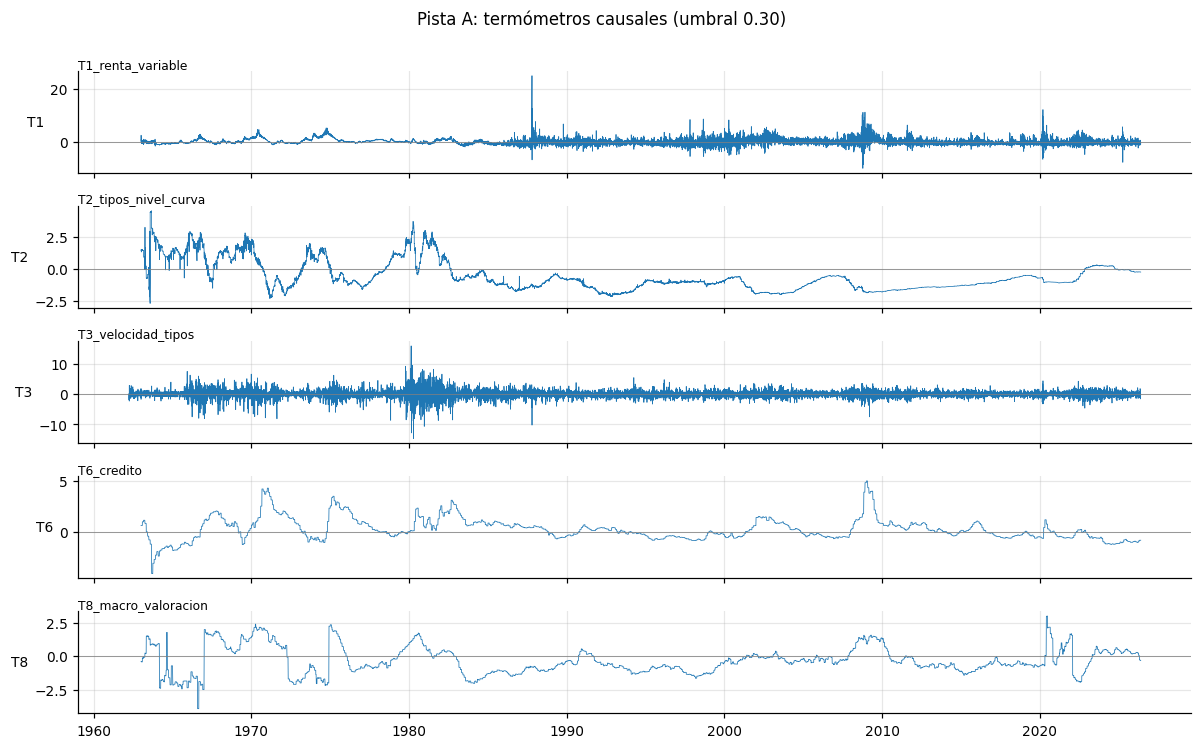

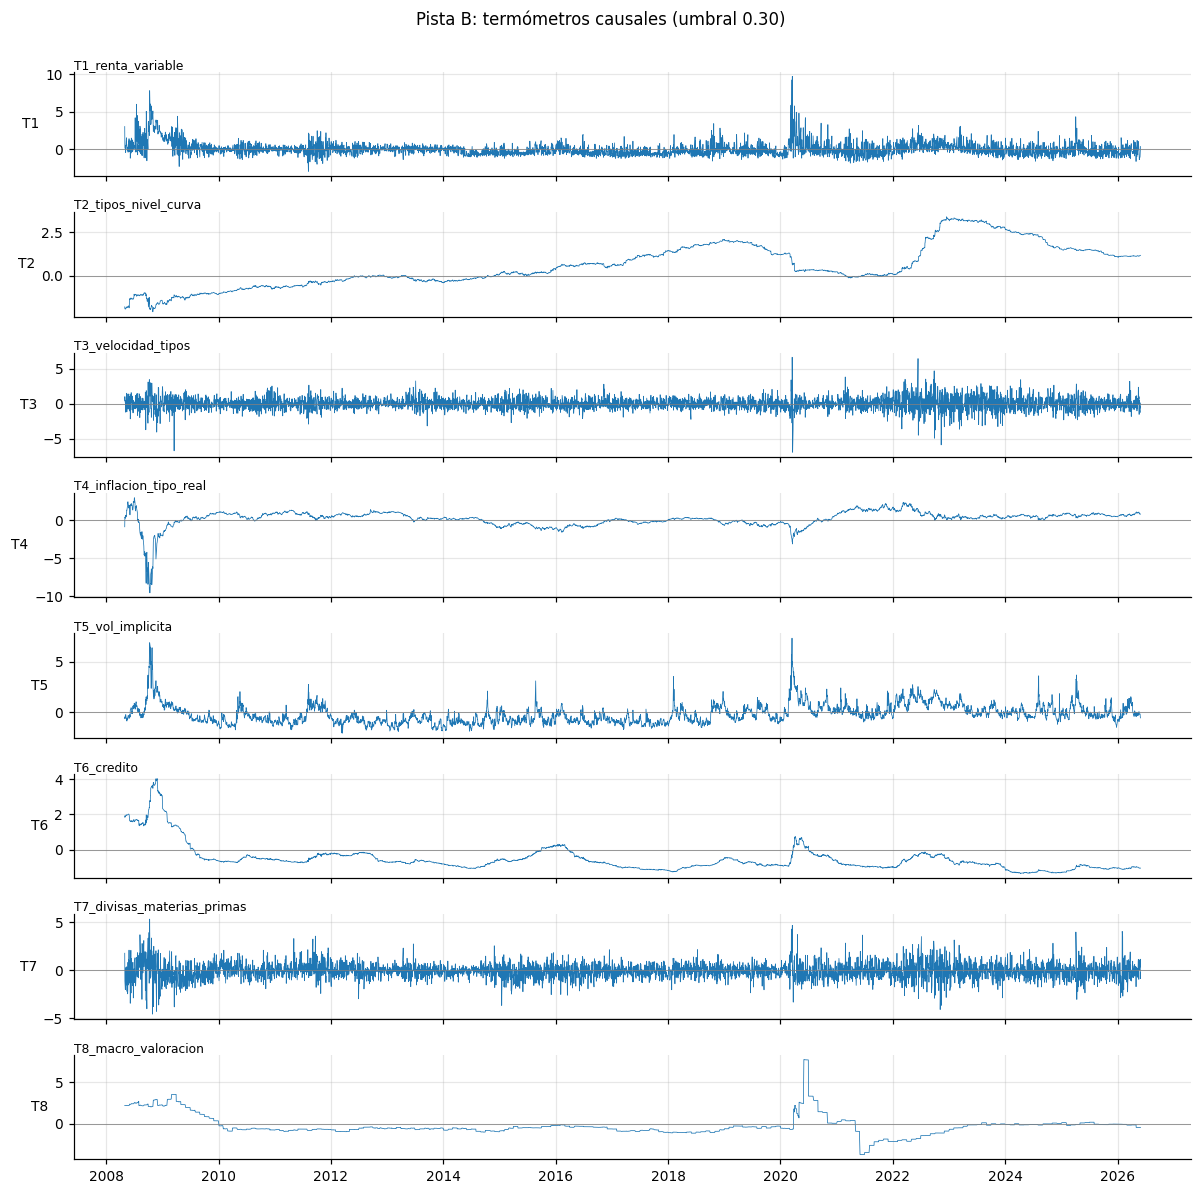

In [6]:
TERM, DIAG = {}, {}
for pista in ('A', 'B'):
    TERM[pista], DIAG[pista] = bq.construir_termometros(PANEL[pista], BLOQUES[pista],
                                                        umbral_var=UMBRAL, min_obs=PARAMS['min_obs'])
    print(f'Pista {pista}: {TERM[pista].shape[1]} termómetros, primer valor por termómetro:')
    print(TERM[pista].apply(lambda s: s.first_valid_index().date()).to_string())

for pista in ('A', 'B'):
    T = TERM[pista]
    fig, axes = plt.subplots(len(T.columns), 1, figsize=(11, 1.35 * len(T.columns)), sharex=True)
    for ax, c in zip(np.atleast_1d(axes), T.columns):
        ax.plot(T.index, T[c], lw=.5, color='C0')
        ax.axhline(0, color='0.5', lw=.5)
        ax.set_ylabel(c.split('_', 1)[0], rotation=0, ha='right', va='center')
        ax.set_title(c, fontsize=8, loc='left', pad=2)
    fig.suptitle(f'Pista {pista}: termómetros causales (umbral {UMBRAL:.2f})', y=1.0)
    plt.tight_layout(); plt.show()

## 6. Validación 2 · sentido estadístico y económico

Criterios propuestos en el ADR-008 §5:

- La PC1 supera el umbral en ≥ 80 % de los reajustes (si no, el bloque funciona como media simple, que
  sigue siendo válida, pero se dice).
- Ninguna columna pesa más del 50 % en ≥ 80 % de los reajustes.
- Coseno mediano entre reajustes consecutivos ≥ 0,9 y sin saltos de signo.
- Signos con lógica económica: se muestran las cargas del último reajuste.

In [7]:
filas = []
for pista in ('A', 'B'):
    res = bq.resumen_estabilidad(TERM[pista], DIAG[pista])
    for _, r in res.iterrows():
        d = DIAG[pista][r['termometro']]
        ok = d[d['metodo'].isin(['pca', 'media'])]
        n = max(len(ok), 1)
        filas.append({
            'pista': pista, 'termometro': r['termometro'], 'n_reajustes': len(ok),
            'frac_pc1_sobre_umbral': (ok['var_pc1'] >= UMBRAL).mean() if len(ok) else np.nan,
            'frac_peso_max_le_50': 1 - r['n_peso_mayor_50'] / n,
            'coseno_mediana': r['coseno_mediana'], 'n_saltos_signo': r['n_saltos_signo'],
            'var_pc1_mediana': r['var_pc1_mediana'], 'ausentes': r['ausentes'],
        })
val2 = pd.DataFrame(filas)
val2['n_columnas'] = [len(BLOQUES[p][t]['columnas']) for p, t in zip(val2['pista'], val2['termometro'])]
val2['pc1_ok'] = val2['frac_pc1_sobre_umbral'] >= .8
val2['peso_ok'] = val2['frac_peso_max_le_50'] >= .8
val2['estable_ok'] = (val2['coseno_mediana'] >= .9) & (val2['n_saltos_signo'] == 0)
# Un bloque de una columna no tiene PCA (es la columna orientada): los criterios no aplican.
# Con dos columnas el peso máximo ronda el 50 % por construcción: ese criterio tampoco aplica.
val2.loc[val2['n_columnas'] == 1, ['pc1_ok', 'peso_ok', 'estable_ok']] = 'n/a'
val2.loc[val2['n_columnas'] == 2, 'peso_ok'] = 'n/a'
display(val2.round(3))

,pista,termometro,n_reajustes,frac_pc1_sobre_umbral,frac_peso_max_le_50,coseno_mediana,n_saltos_signo,var_pc1_mediana,ausentes,n_columnas,pc1_ok,peso_ok,estable_ok
0,A,T1_renta_variable,762,1.000,1.000,1.0,1,0.341,[FF_industry_dispersion_z],7,True,True,False
1,A,T2_tipos_nivel_curva,762,1.000,1.000,1.0,1,0.691,[],10,True,True,False
2,A,T3_velocidad_tipos,0,NaN,1.000,NaN,0,NaN,[],1,n/a,n/a,n/a
3,A,T6_credito,762,1.000,0.349,1.0,0,0.698,[],2,True,n/a,True
4,A,T8_macro_valoracion,762,1.000,1.000,1.0,4,0.431,[CAPE_z],15,True,True,False
5,B,T1_renta_variable,218,0.312,1.000,1.0,2,0.288,"[FF_RMW_z, FF_industry_dispersion_z]",14,False,True,False
6,B,T2_tipos_nivel_curva,218,1.000,1.000,1.0,0,0.681,[],15,True,True,True
7,B,T3_velocidad_tipos,218,1.000,1.000,1.0,0,0.603,[],3,True,True,True
8,B,T4_inflacion_tipo_real,218,1.000,1.000,1.0,0,0.680,[],4,True,True,True
9,B,T5_vol_implicita,218,1.000,1.000,1.0,0,0.399,[],7,True,True,True


In [8]:
def cargas_ultimo(pista, nombre):
    d = DIAG[pista][nombre]
    ok = d[d['metodo'].isin(['pca', 'media'])]
    if ok.empty:
        return pd.Series(dtype=float)
    car = ok['cargas'].iloc[-1]
    return pd.Series(car, dtype=float).sort_values(key=np.abs, ascending=False)

for pista in ('A', 'B'):
    print(f'=== Pista {pista}: cargas del último reajuste (ancla marcada con *)')
    for nombre, b in BLOQUES[pista].items():
        s = cargas_ultimo(pista, nombre)
        anc = b['ancla']['columna']
        txt = ', '.join(f"{'*' if k == anc else ''}{k} {v:+.2f}" for k, v in s.items())
        print(f'{nombre}: {txt}')

=== Pista A: cargas del último reajuste (ancla marcada con *)
T1_renta_variable: SP500_ret_z -0.64, FF_MKT_z -0.64, SP500_drawdown -0.29, SP500_momentum -0.23, *SP500_vol_z +0.19, FF_MOM_z +0.12
T2_tipos_nivel_curva: short_rate_z +0.38, TB3MS_z +0.37, GS1_z +0.37, mid_curve_z +0.36, GS5_z +0.36, GS10_z +0.35, fed_stance_z +0.28, curve_vs_policy_10y_z -0.23, curve_vs_policy_5y_z -0.20, *term_spread_hist_z -0.17
T3_velocidad_tipos: 
T6_credito: credit_BaaFF_z +0.71, *credit_BaaAaa_mensual_z +0.71
T8_macro_valoracion: PPI_yoy_z -0.42, CPI_yoy_z -0.39, PPI_fuels_yoy_z -0.36, WTI_yoy_z -0.34, CPI_core_yoy_z -0.30, PAYEMS_chg_z -0.25, GW_valuation_z -0.24, MANEMP_yoy_z -0.22, PPI_metals_yoy_z -0.21, INDPRO_yoy_z -0.21, *UNRATE_chg_z +0.20, UMCSENT_z +0.18, HOUST_yoy_z +0.07, GDP_growth_z -0.05
=== Pista B: cargas del último reajuste (ancla marcada con *)
T1_renta_variable: SP500_ret_z -0.29, *SP500_vol_z +0.29, SP500_momentum -0.29, SP500_drawdown -0.29, SP500_megacap_gap_z +0.29, equity_bre

## 7. Validación 3 · validez externa

Correlación de cada termómetro con los índices de estrés `rol=validation` de `data/raw`, alineados a la
rejilla de la pista con el último dato disponible. Son índices construidos por terceros (Fed de Chicago,
OFR, Fed de St. Louis y Kansas City) que **nunca** entran como features. Pares de referencia propuestos:
T6 con `NFCI_CREDIT` y `OFR_FSI_CREDIT`; T5 con `OFR_FSI_VOLATILITY` y `VIX_VALIDATION_REF`; T1 con
`NFCI_RISK`; T7 con `OFR_FSI_FUNDING` (orientativo). Criterio propuesto: |ρ| ≥ 0,3 con su referencia.

Índices de validación cargados: 12 | faltan: []


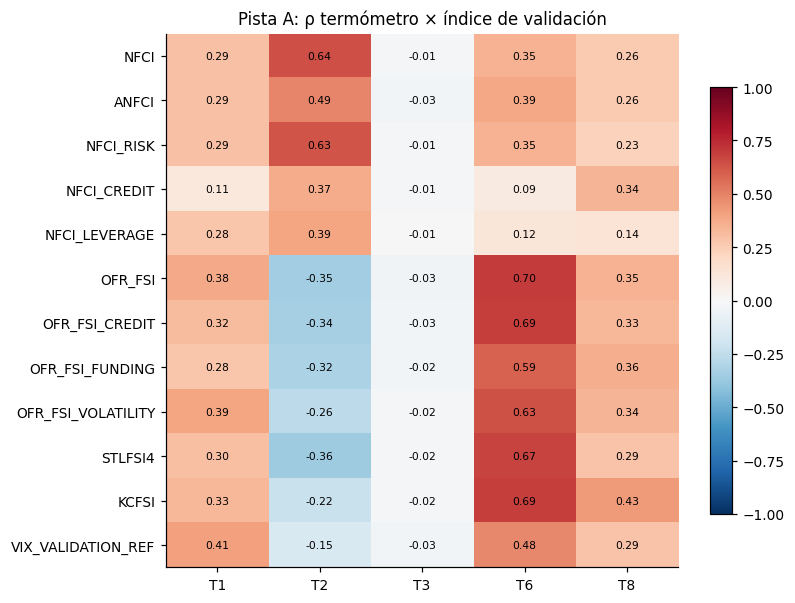

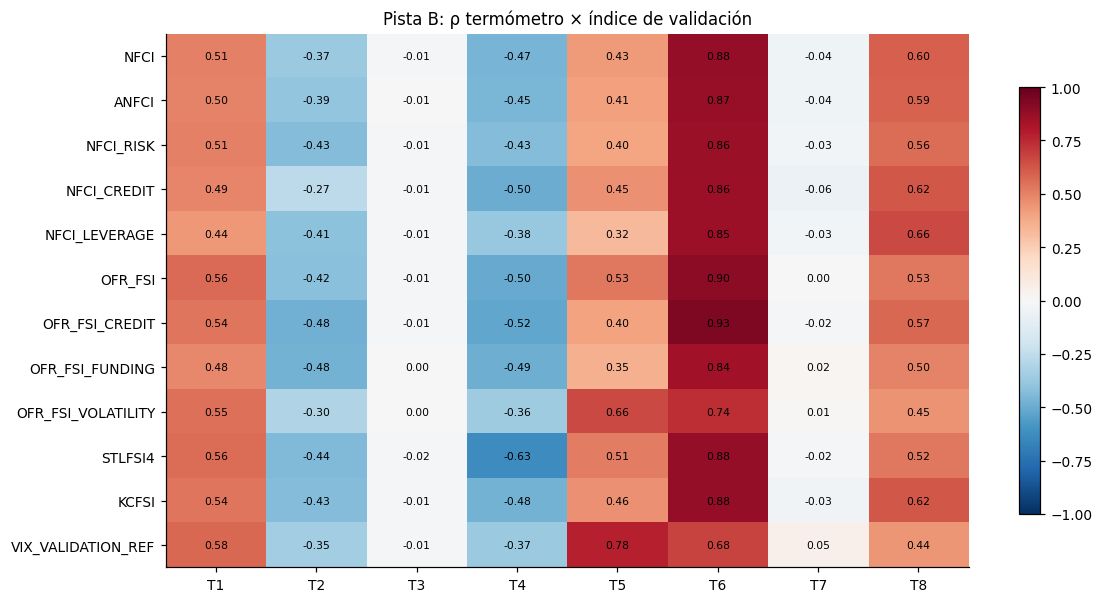

,pista,termometro,referencia,rho,ok_abs_ge_0.3
0,A,T1_renta_variable,NFCI_RISK,0.293,False
1,A,T1_renta_variable,STLFSI4,0.303,True
2,A,T6_credito,NFCI_CREDIT,0.086,False
3,A,T6_credito,OFR_FSI_CREDIT,0.688,True
4,B,T1_renta_variable,NFCI_RISK,0.506,True
5,B,T1_renta_variable,STLFSI4,0.559,True
6,B,T5_vol_implicita,OFR_FSI_VOLATILITY,0.660,True
7,B,T5_vol_implicita,VIX_VALIDATION_REF,0.780,True
8,B,T6_credito,NFCI_CREDIT,0.856,True
9,B,T6_credito,OFR_FSI_CREDIT,0.934,True


In [9]:
VALID = ['NFCI', 'ANFCI', 'NFCI_RISK', 'NFCI_CREDIT', 'NFCI_LEVERAGE', 'OFR_FSI', 'OFR_FSI_CREDIT',
         'OFR_FSI_FUNDING', 'OFR_FSI_VOLATILITY', 'STLFSI4', 'KCFSI', 'VIX_VALIDATION_REF']
val_crudo, val_faltan = carga(VALID)
print('Índices de validación cargados:', len(val_crudo), '| faltan:', val_faltan)

def alinear(s, index):
    s = s.squeeze() if isinstance(s, pd.DataFrame) else s
    return s.sort_index().reindex(s.index.union(index)).ffill().reindex(index)

CORR = {}
for pista in ('A', 'B'):
    T = TERM[pista]
    V = pd.DataFrame({n: alinear(s, T.index) for n, s in val_crudo.items()})
    CORR[pista] = pd.DataFrame({v: T.corrwith(V[v]) for v in V.columns}).T
    fig, ax = plt.subplots(figsize=(1.1 * T.shape[1] + 2, .38 * len(V.columns) + 1))
    im = ax.imshow(CORR[pista].values, cmap='RdBu_r', vmin=-1, vmax=1, aspect='auto')
    ax.set_xticks(range(T.shape[1]), [c.split('_', 1)[0] for c in T.columns])
    ax.set_yticks(range(len(V.columns)), V.columns)
    for i in range(CORR[pista].shape[0]):
        for j in range(CORR[pista].shape[1]):
            ax.text(j, i, f'{CORR[pista].iat[i, j]:.2f}', ha='center', va='center', fontsize=7)
    fig.colorbar(im, ax=ax, shrink=.8); ax.set_title(f'Pista {pista}: ρ termómetro × índice de validación')
    ax.grid(False); plt.tight_layout(); plt.show()

REF = {'T1_renta_variable': ['NFCI_RISK', 'STLFSI4'], 'T5_vol_implicita': ['OFR_FSI_VOLATILITY', 'VIX_VALIDATION_REF'],
       'T6_credito': ['NFCI_CREDIT', 'OFR_FSI_CREDIT'], 'T7_divisas_materias_primas': ['OFR_FSI_FUNDING']}
filas = []
for pista in ('A', 'B'):
    for t, refs in REF.items():
        for r in refs:
            if t in CORR[pista].columns and r in CORR[pista].index:
                rho = CORR[pista].loc[r, t]
                filas.append({'pista': pista, 'termometro': t, 'referencia': r, 'rho': rho,
                              'ok_abs_ge_0.3': abs(rho) >= .3})
display(pd.DataFrame(filas).round(3))

## 8. Calentamiento: historia anterior a la ventana (punto abierto del ADR-008)

Con `min_obs = 252` el termómetro no tiene valor hasta un año después del inicio del panel. En la pista B
eso retrasaría el OOS del menú T frente al del menú N. Opción (a) del ADR-008: construir el panel desde
antes de `ventana_inicio` (solo pasado, sigue siendo causal) y recortar a la ventana. Aquí se mide cuánto
adelanta el primer valor en B si el panel arranca tres años antes.

In [10]:
ini_B = pd.Timestamp(BENCH['pista_B']['ventana_inicio'])
panel_ext, _, _ = panel_pista('B', inicio=str((ini_B - pd.DateOffset(years=3)).date()))
T_ext, _ = bq.construir_termometros(panel_ext, BLOQUES['B'], umbral_var=UMBRAL, min_obs=PARAMS['min_obs'])
T_ext = T_ext.loc[ini_B:]
primeros = pd.DataFrame({
    'desde_ventana': TERM['B'].apply(lambda s: s.first_valid_index()),
    'con_3_años_previos': T_ext.apply(lambda s: s.first_valid_index()),
})
primeros['dias_ganados'] = (primeros['desde_ventana'] - primeros['con_3_años_previos']).dt.days
display(primeros)
comunes = TERM['B'].dropna().index.intersection(T_ext.dropna().index)
print('Correlación entre ambas versiones en el tramo común:',
      T_ext.loc[comunes].corrwith(TERM['B'].loc[comunes]).round(3).to_dict())

,desde_ventana,con_3_años_previos,dias_ganados
T1_renta_variable,2008-05-01,2007-04-11,386
T2_tipos_nivel_curva,2008-05-01,2007-04-11,386
T3_velocidad_tipos,2008-05-01,2007-04-11,386
T4_inflacion_tipo_real,2008-05-01,2007-04-11,386
T5_vol_implicita,2008-05-01,2007-04-11,386
T6_credito,2008-05-01,2007-04-11,386
T7_divisas_materias_primas,2008-05-01,2007-04-11,386
T8_macro_valoracion,2008-05-01,2007-04-11,386


Correlación entre ambas versiones en el tramo común: {'T1_renta_variable': 0.652, 'T2_tipos_nivel_curva': 0.988, 'T3_velocidad_tipos': 0.995, 'T4_inflacion_tipo_real': 0.923, 'T5_vol_implicita': 1.0, 'T6_credito': 0.985, 'T7_divisas_materias_primas': 0.994, 'T8_macro_valoracion': 0.987}


## 9. Conclusiones y pendientes

**Validación 1 (cálculo).** Correcto y causal: factor recuperado (ρ ≈ 0,87 con ruido), prefijo exacto,
signo de la ancla estable y NaN contenidos. Lo mismo que los 29 tests de `tests/features/test_bloques.py`.

**Umbral.** La regla provisional elige **30 %** (12 incidencias frente a 25 y 16). Ojo: la regla favorece
por construcción el umbral más bajo, que cambia menos entre PCA y media. A 30 % casi todo es PCA; a 40–50 %
T1 (B), T5 (B), T7 (B) y T8 pasan a media en muchos tramos. Hay que confirmarla en el ADR-008.

**Validación 2 (sentido estadístico y económico).**

- *Pista B:* T2 a T8 cumplen (PC1 por encima del umbral, ningún peso > 50 %, cargas estables, sin saltos de
  signo). Los signos tienen lógica: T3 = subidas rápidas del 10 años nominal y real; T4 = breakevens; T5 = VIX
  y MOVE arriba con la curva del VIX invertida; T6 = los cuatro spreads Baa; T7 = dólar, franco y yen arriba
  con materias primas y AUD abajo (*risk-off*); T8 = actividad cayendo y paro subiendo.
- **T1 (B) no cumple:** la PC1 solo explica ~29 % y el 69 % de los tramos usa la media. El bloque mezcla
  rentabilidades diarias (`SP500_ret_z`, `FF_MKT_z`, `FF_MOM_z`) con niveles (vol, drawdown, momentum), y en
  la media las rentabilidades se orientan por su correlación con la vol, que es casi nula: los signos son
  frágiles (ρ = 0,65 entre las dos versiones de la sección 8). **Propuesta:** quitar las rentabilidades
  diarias de T1 o cambiar la ancla a `SP500_drawdown`.
- *Pista A:* T1 lo dominan las rentabilidades (la vol carga solo +0,19) y T8 lo domina la inflación con el
  paro como ancla débil (4 saltos de signo). Hay que revisar ambas anclas. T6 tiene 2 columnas (el criterio
  del 50 % no aplica) y T3 es una sola columna.
- `HYG_IEF` y `HYG_LQD` cargan ~0 en T6 (B): probablemente son diferencias de rentabilidad diaria y no
  niveles de spread; revisar su definición.

**Validación 3 (validez externa).** Muy buena en B: T6 con `OFR_FSI_CREDIT` ρ = 0,93 y con `NFCI_CREDIT`
0,86; T5 con el VIX 0,78 y con `OFR_FSI_VOLATILITY` 0,66; T1 con `STLFSI4` 0,56. En A, T6 con
`OFR_FSI_CREDIT` 0,69, pero con `NFCI_CREDIT` solo 0,09, y T1 ronda 0,30. El par T7–`OFR_FSI_FUNDING` era
una apuesta y no se cumple (0,02).

**Calentamiento.** Con tres años de historia previa, los 8 termómetros de B tienen valor desde el primer día
de la ventana (386 días ganados) y coinciden con la versión corta (ρ ≥ 0,92) salvo T1. **La opción (a) del
ADR-008 funciona.**

Pendiente para la versión oficial (portátil principal):

1. Repetir sobre `data/processed` verificado con los sha256 de `03_preprocesado`, con `CAPE_z`,
   `FF_industry_dispersion_z` y `FF_RMW_z`.
2. Decidir T1 (B) y las anclas de T1 y T8 (A); confirmar umbral y calentamiento (a) en el ADR-008.
3. Congelar el ADR-008 antes de ejecutar detectores con el menú T.